In [126]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [127]:
df = pd.read_csv("modelling.csv")

In [128]:
df['Open'].unique()

array([1])

## Feature Engineering

In the Rossman Sales dataset PromoInterval tells us which months recurring promotion (promo 2) is running.
If a store participates in Promo2 (meaning the Promo2 column is 1), it doesn't run the promotion every single day of the year. Instead, the promotion runs in a 3-month repeating cycle.

IsPromo2Active- tells the model whether a store's recurring promotion (Promo2) is active on a particular date.
-equals 1 when the store participates in Promo2, the programme has started, and the month is listed in PromoInterval. Otherwise, it equals 0.


In [129]:
df['Date'] = pd.to_datetime(df['Date'])

# Months in which the store starts a new Promo2 promotion
df['IsPromo2Active'] = df.apply(
    lambda row: int(
        row['Promo2'] == 1
        and pd.notna(row['PromoInterval'])
        and row['Date'].strftime('%b') in row['PromoInterval'].split(',')
        and row['Date'].isocalendar().year * 100
            + row['Date'].isocalendar().week
            >= row['Promo2SinceYear'] * 100
            + row['Promo2SinceWeek']
    ) if pd.notna(row['Promo2SinceYear'])
        and pd.notna(row['Promo2SinceWeek'])
        else 0,
    axis=1
)


In [130]:
df['IsPromo2Active'].unique()

array([0, 1])

Day 7 is adjacent to day 1 of the week (eg. monday is adjacent to sunday but the numbers make it seem like they are far apart)
So using sin/cos of month/dayofweek makes the month/dayofweek cyclic
sin and cos are used because for some values sin is 0 and for those values sin is not 0
This may imporve the performance of an mlp

In [131]:
# Day of week: 7-day cycle
df['DayOfWeek_sin'] = np.sin(2 * np.pi * df['DayOfWeek'] / 7)
df['DayOfWeek_cos'] = np.cos(2 * np.pi * df['DayOfWeek'] / 7)

# Month: 12-month cycle
df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)

In [132]:
# Remove open because all the stores we have in our final dataset is open

X = df[['DayOfWeek_sin',
    'DayOfWeek_cos',
    'Month_sin',
    'Month_cos',
    'Promo',
    'StateHoliday',
    'SchoolHoliday',
    'StoreType',
    'Assortment',
    'CompetitionDistance',
    'CompetitionOpenSinceMonth',
    'CompetitionOpenSinceYear',
    'Promo2',
    'Promo2SinceWeek',
    'Promo2SinceYear',
    'Year',
    'Month',
    'Day',
    'WeekOfYear',
    'IsPromo2Active',
    'Store']]
Y = df['Sales']



##Scaling/One-hot encoding


In [133]:

from sklearn.preprocessing import OneHotEncoder, StandardScaler
import pandas as pd

import pandas as pd

# 1. Create Date and sort chronologically
df = df.copy()
df['Date'] = pd.to_datetime(df[['Year', 'Month', 'Day']])
df = df.sort_values('Date').reset_index(drop=True)

# 2. Use the last 4 weeks (28 days) for testing
latest_date = df['Date'].max()
cutoff = latest_date - pd.Timedelta(weeks=4)

train_df = df[df['Date'] < cutoff].copy()
test_df = df[df['Date'] >= cutoff].copy()

# 3. Check the split
print("Training period:", train_df['Date'].min(), "to", train_df['Date'].max())
print("Testing period:", test_df['Date'].min(), "to", test_df['Date'].max())
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("Training unique dates:", train_df['Date'].nunique())
print("Testing unique dates:", test_df['Date'].nunique())

# 3. Define target and features
target_col = 'Sales'

categorical_cols = [
    'StateHoliday', 'StoreType', 'Assortment', 'Store'
]

numerical_cols = [
    'DayOfWeek_sin', 'DayOfWeek_cos',
    'Month_sin', 'Month_cos',
    'CompetitionDistance',
    'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear',
    'Promo2SinceWeek', 'Promo2SinceYear',
    'Year', 'Month', 'Day', 'WeekOfYear'
]

binary_cols = [
    'Open', 'Promo', 'SchoolHoliday',
    'Promo2', 'IsPromo2Active'
]

feature_cols = categorical_cols + numerical_cols + binary_cols

X_train = train_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_df[target_col].copy()
y_test = test_df[target_col].copy()

# 4. One-hot encode categorical variables
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

X_train_cat = pd.DataFrame(
    encoder.fit_transform(X_train[categorical_cols]),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    encoder.transform(X_test[categorical_cols]),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_test.index
)

# 5. Standardise numerical variables
scaler = StandardScaler()

X_train_num = pd.DataFrame(
    scaler.fit_transform(X_train[numerical_cols]),
    columns=numerical_cols,
    index=X_train.index
)

X_test_num = pd.DataFrame(
    scaler.transform(X_test[numerical_cols]),
    columns=numerical_cols,
    index=X_test.index
)

# 6. Keep binary variables unchanged
X_train_bin = X_train[binary_cols].copy()
X_test_bin = X_test[binary_cols].copy()

# 7. Combine processed features
X_train_processed = pd.concat(
    [X_train_num, X_train_cat, X_train_bin], axis=1
)

X_test_processed = pd.concat(
    [X_test_num, X_test_cat, X_test_bin], axis=1
)

# 8. Verify alignment and shapes
assert X_train_processed.columns.equals(X_test_processed.columns)
assert X_train_processed.index.equals(y_train.index)
assert X_test_processed.index.equals(y_test.index)

print("Processed train:", X_train_processed.shape)
print("Processed test:", X_test_processed.shape)
print("Cutoff date:", pd.Timestamp(cutoff))


Training period: 2013-01-01 00:00:00 to 2015-07-02 00:00:00
Testing period: 2015-07-03 00:00:00 to 2015-07-31 00:00:00
Train shape: (169376, 27)
Test shape: (5624, 27)
Training unique dates: 913
Testing unique dates: 29
Processed train: (169376, 252)
Processed test: (5624, 252)
Cutoff date: 2015-07-03 00:00:00


In [134]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

# Check for missing values
print("Missing values in training features:",
      X_train_processed.isna().sum().sum())

print("Missing values in test features:",
      X_test_processed.isna().sum().sum())

Missing values in training features: 0
Missing values in test features: 0


##MLP

In [73]:
from sklearn.neural_network import MLPRegressor

mlp = MLPRegressor(
 hidden_layer_sizes= (20,20),
 activation = 'relu',
 solver = 'adam',
 max_iter = 5000,
 early_stopping=True,
 random_state = 0,
 n_iter_no_change=20
)
mlp.fit(X_train_processed, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(20, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",5000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",0
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by atleast ``tol`` for ``n_iter_no_change`` consecutive epochs.Only effective when solver='sgd' or 'adam'.",True
,"n_iter_no_change n_iter_no_change: int, default=10Maximum number of epochs to not meet ``tol`` improvement.Only effective when solver='sgd' or 'adam'... versionadded:: 0.20",20
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to de

In [74]:
Y_pred_test = mlp.predict(X_test_processed)
Y_pred_train = mlp.predict(X_train_processed)

In [75]:
# 2. Evaluate Training Set Metrics
train_mae = mean_absolute_error(y_train, Y_pred_train)
train_rmse = root_mean_squared_error(y_train, Y_pred_train)
train_r2 = r2_score(y_train,Y_pred_train)


# 3. Evaluate Testing Set Metrics
test_mae = mean_absolute_error(y_test, Y_pred_test)
test_rmse = root_mean_squared_error(y_test, Y_pred_test)
test_r2 = r2_score(y_test, Y_pred_test)

In [76]:
print("--- Training Metrics ---")
print(f"MAE : {train_mae}")
print(f"RMSE: {train_rmse}")
print(f"R2  : {train_r2}\n")

print("--- Testing Metrics ---")
print(f"MAE : {test_mae}")
print(f"RMSE: {test_rmse}")
print(f"R2  : {test_r2}")

--- Training Metrics ---
MAE : 832.3827631211454
RMSE: 1185.8858033492306
R2  : 0.896156996348124

--- Testing Metrics ---
MAE : 1022.5855810179246
RMSE: 1389.699004832141
R2  : 0.8377772378880484


##Multivariate Linear Regression


In [77]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

In [78]:
linear = LinearRegression()  # Instantatiate the linear regression model
linear.fit(X_train_processed,y_train)  # Fit the model parameters to the training data.

# Evaluate model performance.
training_predictions = linear.predict(X_train_processed)  # Get model predictions for both.
testing_predictions = linear.predict(X_test_processed)    # training and testing data.

# Create a table of the various scores.
results = pd.DataFrame({
    "R^2": {
        "train": r2_score(y_train, training_predictions),
        "test": r2_score(y_test, testing_predictions)
    },
    "RMSE": {
        "train": root_mean_squared_error(y_train, training_predictions),
        "test": root_mean_squared_error(y_test, testing_predictions)
    },
    "MAE": {
        "train": mean_absolute_error(y_train, training_predictions),
        "test": mean_absolute_error(y_test, testing_predictions)
    }
})

In [79]:
Y_pred_test = mlp.predict(X_test_processed)
Y_pred_train = mlp.predict(X_train_processed)

In [80]:
print(results)

            R^2         RMSE          MAE
train  0.706807  1992.648818  1455.836881
test   0.714033  1845.111951  1363.006452


In [81]:
feature_names = X_train_processed.columns.tolist() # write the column names to a list

# create a Series for which the rows are the feature names and the data is
# the regression coefficient values
coefficients = pd.Series(data=linear.coef_.transpose(), index=feature_names)
print(coefficients)

DayOfWeek_sin          1.791470e+02
DayOfWeek_cos          6.048732e+02
Month_sin              8.751225e+02
Month_cos              3.072071e+01
CompetitionDistance   -6.161463e+02
                           ...     
Open                  -5.684342e-13
Promo                  3.339025e+03
SchoolHoliday          5.955622e+02
Promo2                -2.213339e+02
IsPromo2Active        -1.411176e+02
Length: 252, dtype: float64


##Ridge_2


In [82]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

##Lasoo_2

##Ridge Regression



##Lasso regularisation

##Random Forest

In [101]:

store_cols = [c for c in X_train_processed.columns if c.startswith('Store_')]
X_train_processed = X_train_processed.drop(columns=store_cols)
X_test_processed = X_test_processed.drop(columns=store_cols)

X_train_processed['Store'] = train_df.loc[X_train_processed.index, 'Store'].astype('category')
X_test_processed['Store'] = pd.Categorical(test_df.loc[X_test_processed.index, 'Store'],
                                           categories=X_train_processed['Store'].cat.categories)

extra = ['DaysSincePrevOpen', 'DaysToNextOpen', 'PromoDay']
if all(c in train_df.columns for c in extra):
    X_train_processed[extra] = train_df.loc[X_train_processed.index, extra].values
    X_test_processed[extra] = test_df.loc[X_test_processed.index, extra].values

print(X_train_processed.shape, X_test_processed.shape)

(169376, 30) (5624, 30)


In [118]:
from sklearn.ensemble import RandomForestRegressor

In [119]:
forest = RandomForestRegressor(
    n_estimators=128,
    criterion='squared_error',
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.0,
    max_features=1.0,
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    bootstrap=True,
    oob_score=False,
    n_jobs=4,
    random_state=35,
    verbose=0,
    warm_start=False
)


In [120]:
forest.fit(X_train_processed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",128
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",35
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [121]:
Y_pred_test = forest.predict(X_test_processed)
Y_pred_train = forest.predict(X_train_processed)

In [122]:
# 2. Evaluate Training Set Metrics
train_mae = mean_absolute_error(y_train, Y_pred_train)
train_rmse = root_mean_squared_error(y_train, Y_pred_train)
train_r2 = r2_score(y_train,Y_pred_train)


# 3. Evaluate Testing Set Metrics
test_mae = mean_absolute_error(y_test, Y_pred_test)
test_rmse = root_mean_squared_error(y_test, Y_pred_test)
test_r2 = r2_score(y_test, Y_pred_test)

In [123]:
print("--- Training Metrics ---")
print(f"MAE : {train_mae}")
print(f"RMSE: {train_rmse}")
print(f"R2  : {train_r2}\n")

print("--- Testing Metrics ---")
print(f"MAE : {test_mae}")
print(f"RMSE: {test_rmse}")
print(f"R2  : {test_r2}")

--- Training Metrics ---
MAE : 1281.151122385624
RMSE: 1755.1880456984613
R2  : 0.7725223116650404

--- Testing Metrics ---
MAE : 1377.0373283652493
RMSE: 1861.743430883247
R2  : 0.7088545824821362


0     0.027674
1     0.070890
2     0.005299
3     0.014797
4     0.182228
5     0.034738
6     0.056266
7     0.020813
8     0.015066
9     0.011951
10    0.013104
11    0.050017
12    0.039450
13    0.004271
14    0.000300
15    0.000061
16    0.000019
17    0.007765
18    0.010326
19    0.009484
20    0.009482
21    0.011144
22    0.000968
23    0.006872
24    0.000000
25    0.194384
26    0.005763
27    0.004933
28    0.000841
29    0.191094
dtype: float64


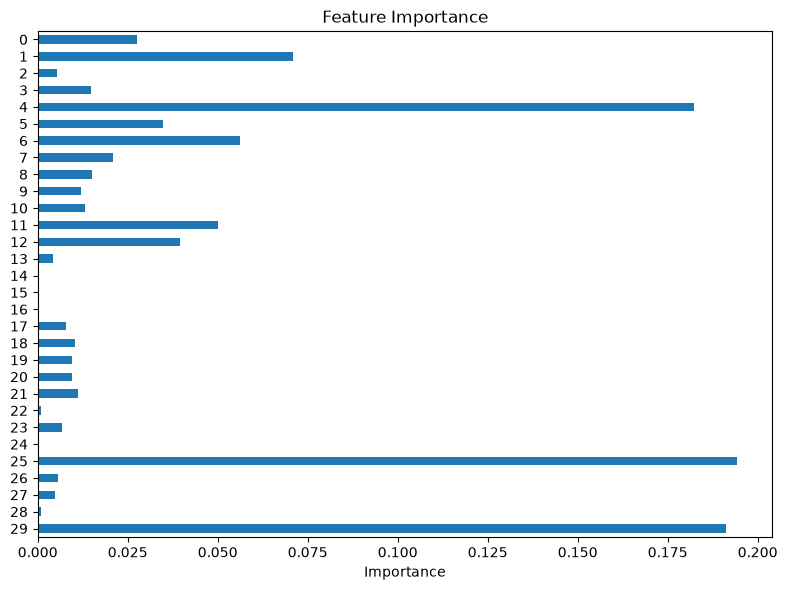

In [108]:
importances = pd.Series(forest.feature_importances_)
print(importances)

importances.plot(kind='barh', figsize=(8, 6))
plt.title('Feature Importance')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

##LightGBM

Uses ensemble of decision trees like random forest, but
- random forest uses bagging
- LightGBM uses boosting as its core ensemble strategy
- LightGBM trees are fitting by optimising a loss function
- Unlike random forest LightGBM splits the leaves that offers the greates reduction in loss. This can produce a more accurate tree for a given number of leaves, but also more complex, unbalanced trees that overfit if left unconstrained.
- in random forest trees are build indpendently, in LighGBM trees are built sequentialy

Random Forest: Ask many independent decision trees for their predictions, then average them to obtain a more stable result.

LightGBM: Build a first prediction, examine how wrong the ensemble is, add a tree to reduce that error, and repeat.

In [135]:
pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [136]:
from lightgbm import LGBMRegressor as lgb

In [137]:
import warnings; warnings.filterwarnings('ignore', message='.*eval_set.*deprecated')

val_start = train_df['Date'].max() - pd.Timedelta(weeks=4)
fit_rows = (train_df['Date'] <= val_start).values
X_fit, y_fit = X_train_processed[fit_rows], y_train[fit_rows]
X_val, y_val = X_train_processed[~fit_rows], y_train[~fit_rows]

tuning = []
for leaves in [31, 63, 127]: #in range of what the standard leaves are 
    for min_child in [30, 100]: 
        for colsample in [0.8, 1.0]: #testing to see impact of changing % of visible trees
            m = lgb(objective='regression', n_estimators=5000, learning_rate=0.05, num_leaves=leaves,
                    min_child_samples=min_child, colsample_bytree=colsample, subsample=0.8, subsample_freq=1,
                    reg_lambda=1.0, random_state=42, verbosity=-1)
            m.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], eval_metric='rmse',
                  callbacks=[lightgbm.early_stopping(200, verbose=False)])   # stop when 200 more trees don't help
            tuning.append({'num_leaves': leaves, 'min_child_samples': min_child, 'colsample_bytree': colsample,
                           'best_trees': m.best_iteration_,
                           'val_R2': r2_score(y_val, m.predict(X_val, num_iteration=m.best_iteration_))})
            print(tuning[-1])

tuning = pd.DataFrame(tuning).sort_values('val_R2', ascending=False)
print(tuning.round(4).to_string(index=False))
best = tuning.iloc[0]

{'num_leaves': 31, 'min_child_samples': 30, 'colsample_bytree': 0.8, 'best_trees': 3205, 'val_R2': 0.8756383760304757}
{'num_leaves': 31, 'min_child_samples': 30, 'colsample_bytree': 1.0, 'best_trees': 2382, 'val_R2': 0.8731032201672155}
{'num_leaves': 31, 'min_child_samples': 100, 'colsample_bytree': 0.8, 'best_trees': 3026, 'val_R2': 0.8694621823456342}
{'num_leaves': 31, 'min_child_samples': 100, 'colsample_bytree': 1.0, 'best_trees': 3448, 'val_R2': 0.8676263318457539}
{'num_leaves': 63, 'min_child_samples': 30, 'colsample_bytree': 0.8, 'best_trees': 1602, 'val_R2': 0.8708008786911754}
{'num_leaves': 63, 'min_child_samples': 30, 'colsample_bytree': 1.0, 'best_trees': 1800, 'val_R2': 0.8616046999955247}
{'num_leaves': 63, 'min_child_samples': 100, 'colsample_bytree': 0.8, 'best_trees': 1227, 'val_R2': 0.8610744177924512}
{'num_leaves': 63, 'min_child_samples': 100, 'colsample_bytree': 1.0, 'best_trees': 1600, 'val_R2': 0.854864872875656}
{'num_leaves': 127, 'min_child_samples': 30, 

In [138]:
lgbm2 = lgb(objective='regression', n_estimators=int(best['best_trees']), learning_rate=0.05,
           num_leaves=int(best['num_leaves']), min_child_samples=int(best['min_child_samples']),
           colsample_bytree=1, subsample=0.8, subsample_freq=1,
           reg_lambda=1.0, random_state=42, verbosity=-1)
lgbm2.fit(X_train_processed, y_train)

,learning_rate,0.05
,n_estimators,3205
,objective,'regression'
,min_child_samples,30
,subsample,0.8
,subsample_freq,1
,reg_lambda,1.0
,random_state,42
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31


In [139]:
predictions = lgbm.predict(X_test_processed)
train = lgbm.predict(X_train_processed)
print("Scores for training ")

print("R²:", r2_score(y_train, train))
print("MAE:", mean_absolute_error(y_train, train))
print("RMSE:", root_mean_squared_error(y_train, train))

print("Scores for testing")
print("R²:", r2_score(y_test, predictions))
print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", root_mean_squared_error(y_test, predictions))

Scores for training 
R²: 0.9683971085993253
MAE: 464.54598560549834
RMSE: 654.2107235064303
Scores for testing
R²: 0.8895996593617725
MAE: 821.6873370159416
RMSE: 1146.4366393189844


In [95]:
lgbm = lgb(
    objective="regression",
    n_estimators=10000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=30,
    colsample_bytree=1,
    subsample=0.8,
    subsample_freq=1,
    reg_lambda=1.0,
    random_state=42,
    verbosity=-1
)
lgbm.fit(X_train_processed, y_train)

,learning_rate,0.05
,n_estimators,10000
,objective,'regression'
,min_child_samples,30
,subsample,0.8
,subsample_freq,1
,reg_lambda,1.0
,random_state,42
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31


In [96]:
predictions = lgbm.predict(X_test_processed)
train = lgbm.predict(X_train_processed)
print("Scores for training ")

print("R²:", r2_score(y_train, train))
print("MAE:", mean_absolute_error(y_train, train))
print("RMSE:", root_mean_squared_error(y_train, train))

print("Scores for testing")
print("R²:", r2_score(y_test, predictions))
print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", root_mean_squared_error(y_test, predictions))

Scores for traning 
R²: 0.9683971085993253
MAE: 464.54598560549834
RMSE: 654.2107235064303
Scores for testing
R²: 0.8895996593617725
MAE: 821.6873370159416
RMSE: 1146.4366393189844


                  Window                    Dates     R2      RMSE      MAE
Last 4 weeks (main test) 2015-07-03 to 2015-07-31 0.8894 1147.6019 815.8176
     4 weeks before that 2015-06-05 to 2015-07-02 0.8740 1328.7893 925.4801
     8 weeks before that 2015-05-08 to 2015-06-04 0.8668 1303.9127 961.4766

Average over the 3 windows: R2 0.8767, RMSE 1260.10


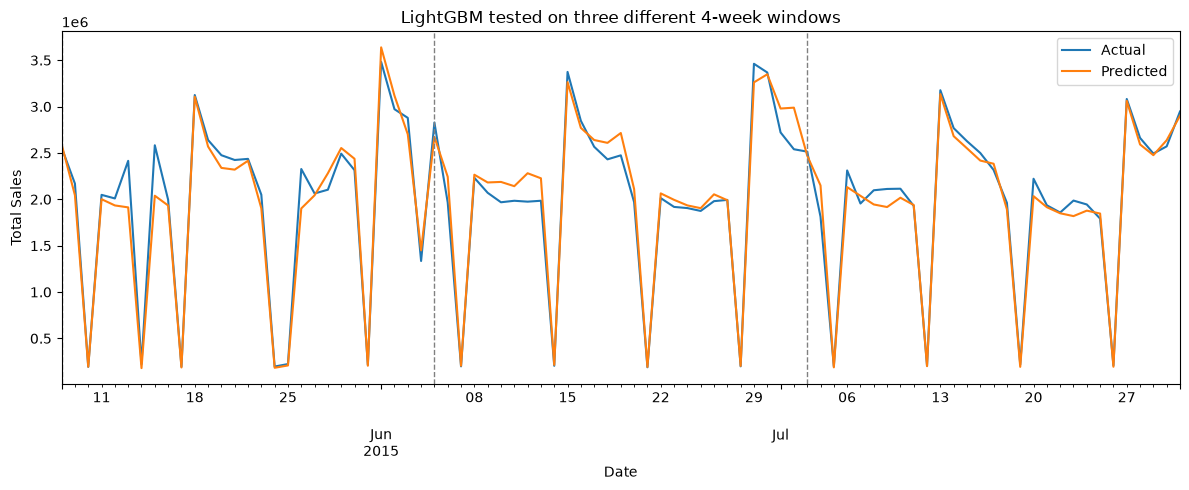

In [140]:
from sklearn.base import clone


X_all = pd.concat([X_train_processed, X_test_processed])
y_all = pd.concat([y_train, y_test])
dates = pd.concat([train_df['Date'], test_df['Date']])
end = dates.max()



starts = [end - pd.Timedelta(weeks=4 * (k + 1)) for k in range(3)]
names = ['Last 4 weeks (main test)', '4 weeks before that', '8 weeks before that']

backtest, daily = [], []
for k, start in enumerate(starts):
    stop = end + pd.Timedelta(days=1) if k == 0 else starts[k - 1]
    train_rows = (dates < start).values                     
    test_rows = ((dates >= start) & (dates < stop)).values   

    m = clone(lgbm2)                                          
    m.fit(X_all[train_rows], y_all[train_rows])
    pred = m.predict(X_all[test_rows])
    actual = y_all[test_rows]

    backtest.append({'Window': names[k],
                     'Dates': f"{dates[test_rows].min().date()} to {dates[test_rows].max().date()}",
                     'R2': r2_score(actual, pred),
                     'RMSE': root_mean_squared_error(actual, pred),
                     'MAE': mean_absolute_error(actual, pred)})
    daily.append(pd.DataFrame({'Date': dates[test_rows].values, 'Actual': actual.values, 'Predicted': pred})
                 .groupby('Date').sum())

backtest = pd.DataFrame(backtest)
print(backtest.round(4).to_string(index=False))
print(f"\nAverage over the 3 windows: R2 {backtest['R2'].mean():.4f}, RMSE {backtest['RMSE'].mean():.2f}")


daily = pd.concat(daily).sort_index()
ax = daily.plot(figsize=(12, 5))
for start in starts:
    ax.axvline(start, color='grey', linestyle='--', linewidth=1)  
plt.title('LightGBM tested on three different 4-week windows')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.savefig('lgbm_three_windows.png', dpi=150, bbox_inches='tight')
plt.show()

                            R2 drop  MSE increase
Feature                                          
Store                      0.631942  7.523271e+06
Promo                      0.417743  4.973236e+06
CompetitionDistance        0.205204  2.442956e+06
DayOfWeek_cos              0.110638  1.317146e+06
DayOfWeek_sin              0.091750  1.092282e+06
Day                        0.047249  5.625005e+05
StoreType                  0.026257  3.125898e+05
Assortment                 0.024635  2.932799e+05
Promo2SinceWeek            0.024564  2.924364e+05
SchoolHoliday              0.009041  1.076322e+05
Promo2SinceYear            0.008747  1.041390e+05
CompetitionOpenSinceYear   0.007508  8.938752e+04
CompetitionOpenSinceMonth  0.006969  8.296221e+04
IsPromo2Active             0.001877  2.235032e+04
Year                       0.000000  0.000000e+00
Month                      0.000000  0.000000e+00
StateHoliday               0.000000  0.000000e+00
Month_cos                  0.000000  0.000000e+00


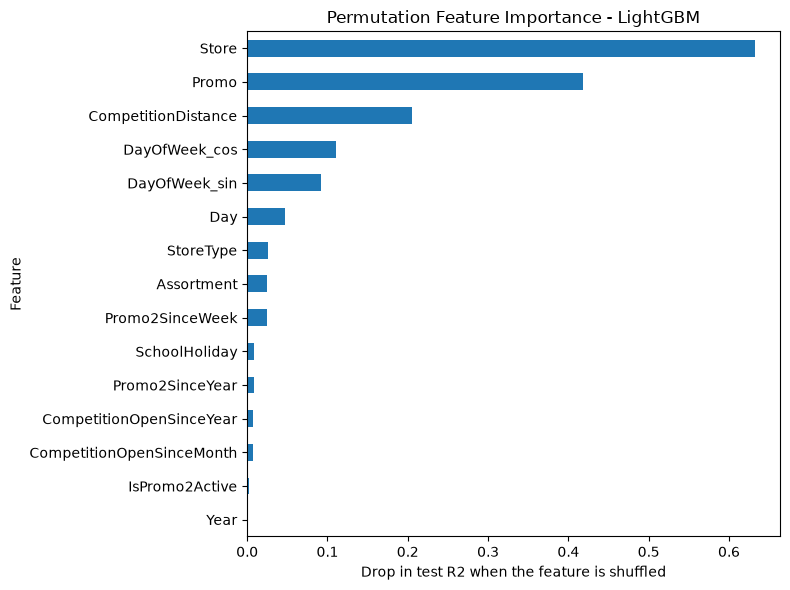

In [98]:

groups = {}
for col in X_test_processed.columns:
    for cat_col in categorical_cols:
        if col.startswith(cat_col + '_'):
            groups.setdefault(cat_col, []).append(col)
            break
    else:
        groups.setdefault(col, []).append(col)

base_pred = lgbm.predict(X_test_processed)
base_r2 = r2_score(y_test, base_pred)
base_mse = mean_squared_error(y_test, base_pred)


rng = np.random.default_rng(0)
rows = []
for feature, cols in groups.items():
    r2_drops, mse_rises = [], []
    for _ in range(3):
        order = rng.permutation(len(X_test_processed))
        X_shuffled = X_test_processed.copy()
        for c in cols:   
            X_shuffled[c] = X_test_processed[c].values[order]
        pred = lgbm.predict(X_shuffled)
        r2_drops.append(base_r2 - r2_score(y_test, pred))
        mse_rises.append(mean_squared_error(y_test, pred) - base_mse)
    rows.append({'Feature': feature, 'R2 drop': np.mean(r2_drops), 'MSE increase': np.mean(mse_rises)})

perm_importance = pd.DataFrame(rows).sort_values('R2 drop', ascending=False).set_index('Feature')
print(perm_importance)

perm_importance['R2 drop'].head(15).plot(kind='barh', figsize=(8, 6))
plt.title('Permutation Feature Importance - LightGBM')
plt.xlabel('Drop in test R2 when the feature is shuffled')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('lgbm_permutation_importance.png', dpi=150, bbox_inches='tight')
plt.show()

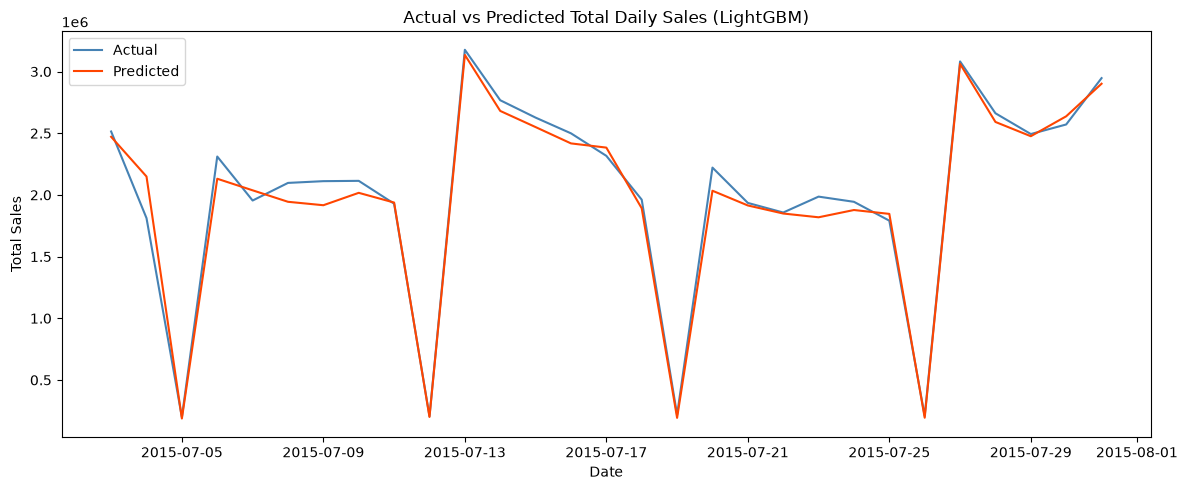

In [141]:
lgbm2.fit(X_train_processed, y_train)      
y_pred = lgbm2.predict(X_test_processed)      

daily_df = pd.DataFrame({
    "Date": test_df["Date"].to_numpy(),
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

daily_df = (
    daily_df.groupby("Date", as_index=False)[["Actual", "Predicted"]]
    .sum()
    .sort_values("Date")
)

plt.figure(figsize=(12, 5))

plt.plot(
    daily_df["Date"], daily_df["Actual"],
    label="Actual", color="steelblue"
)

plt.plot(
    daily_df["Date"], daily_df["Predicted"],
    label="Predicted", color="orangered"
)

plt.title("Actual vs Predicted Total Daily Sales (LightGBM)")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

 Weeks held out  Train rows  Train R2  Test R2  Test RMSE  R2 on final 4 weeks only
              4      169376    0.9684   0.8896  1146.4366                    0.8896
             12      159042    0.9693   0.8648  1323.6365                    0.8676
             20      148817    0.9693   0.8486  1438.6876                    0.8804


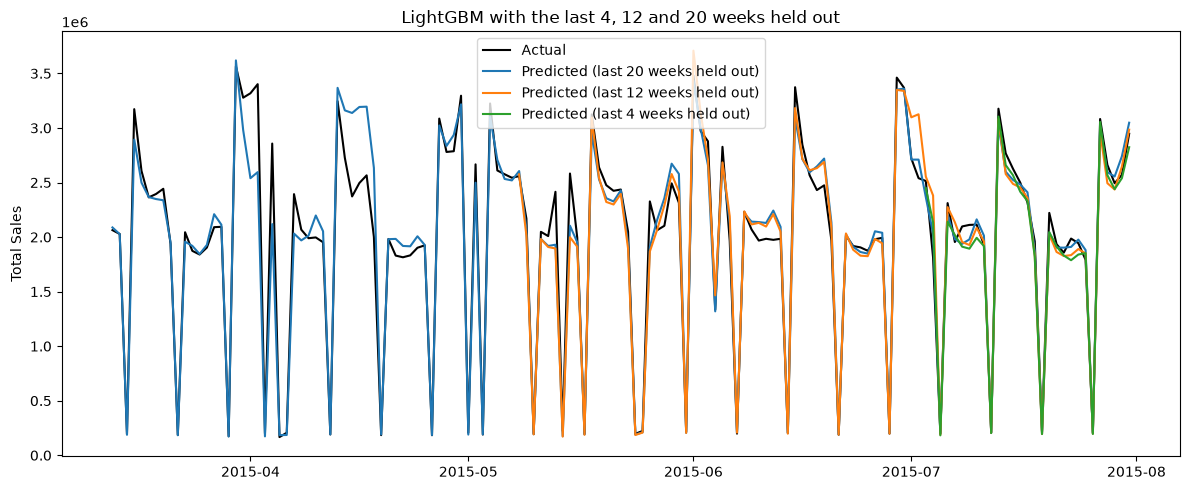

In [142]:
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

X_all = pd.concat([X_train_processed, X_test_processed])
y_all = pd.concat([y_train, y_test])
dates = pd.concat([train_df['Date'], test_df['Date']])
end = dates.max()



last4_cut = end - pd.Timedelta(weeks=4)
in_last4_all = (dates >= last4_cut).values

results, daily, store_level = [], {}, {}
for weeks in [4, 12, 20]:
    cut = end - pd.Timedelta(weeks=weeks)
    train_rows = (dates < cut).values       
    test_rows = (dates >= cut).values       

    m = clone(lgbm)                         
    m.fit(X_all[train_rows], y_all[train_rows])
    pred = m.predict(X_all[test_rows])
    actual = y_all[test_rows]
    train_pred = m.predict(X_all[train_rows])

    in_last4 = in_last4_all[test_rows]     
    results.append({'Weeks held out': weeks,
                    'Train rows': int(train_rows.sum()),
                    'Train R2': r2_score(y_all[train_rows], train_pred),
                    'Test R2': r2_score(actual, pred),
                    'Test RMSE': root_mean_squared_error(actual, pred),
                    'R2 on final 4 weeks only': r2_score(actual[in_last4], pred[in_last4])})

    daily[weeks] = (pd.DataFrame({'Date': dates[test_rows].values, 'Actual': actual.values, 'Predicted': pred})
                    .groupby('Date').sum())
    store_level[weeks] = (dates[test_rows], actual, pred)   # kept for the next cell

results = pd.DataFrame(results)
print(results.round(4).to_string(index=False))

# actual sales and the prediction from each of the three models (total sales across all stores per day)
plt.figure(figsize=(12, 5))
plt.plot(daily[20]['Actual'], color='black', label='Actual')
for weeks, colour in zip([20, 12, 4], ['tab:blue', 'tab:orange', 'tab:green']):
    plt.plot(daily[weeks]['Predicted'], color=colour, label=f'Predicted (last {weeks} weeks held out)')
plt.title('LightGBM with the last 4, 12 and 20 weeks held out')
plt.ylabel('Total Sales')
plt.legend()
plt.tight_layout()
plt.savefig('lgbm_holdout_sizes.png', dpi=150, bbox_inches='tight')
plt.show()